<a href="https://colab.research.google.com/github/michellecarizona/pandas-practice-2/blob/main/pandas_hw_practice_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_style('darkgrid')

In [ ]:
titanic_data = sns.load_dataset('titanic')
titanic_data.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [ ]:
by_class = titanic_data.groupby('class', observed = False)
by_class.size()

,0
class,
First,216
Second,184
Third,491


In [ ]:
by_class.age.min()

,age
class,
First,0.92
Second,0.67
Third,0.42


changed to find the minimum age for each passenger class

new question: What was the average age in each passenger class?

In [ ]:
by_class.age.agg(['max', 'min', 'count', 'median', 'mean'])

,max,min,count,median,mean
class,,,,,
First,80.0,0.92,186,37.0,38.233441
Second,70.0,0.67,173,29.0,29.877630
Third,74.0,0.42,355,24.0,25.140620


In [ ]:
titanic_data.groupby(['class', 'sex'], observed=False)['fare'].mean()

class   sex   
First   female    106.125798
        male       67.226127
Second  female     21.970121
        male       19.741782
Third   female     16.118810
        male       12.661633
Name: fare, dtype: float64

In [ ]:
first_class  = titanic_data[titanic_data["class"] == "First"]
second_class = titanic_data[titanic_data["class"] == "Second"]
third_class = titanic_data[titanic_data["class"] == "Third"]
print("first:",  first_class.shape)
print("second:", second_class.shape)
print("third:", third_class.shape)

first: (216, 15)
second: (184, 15)
third: (491, 15)


In [ ]:
first_class

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
11,1,1,female,58.0,0,0,26.5500,S,First,woman,False,C,Southampton,yes,True
23,1,1,male,28.0,0,0,35.5000,S,First,man,True,A,Southampton,yes,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
871,1,1,female,47.0,1,1,52.5542,S,First,woman,False,D,Southampton,yes,False
872,0,1,male,33.0,0,0,5.0000,S,First,man,True,B,Southampton,no,True
879,1,1,female,56.0,0,1,83.1583,C,First,woman,False,C,Cherbourg,yes,False
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True


added third class

In [ ]:
combined = pd.concat([first_class, second_class], ignore_index=True)
print(combined.shape)

(400, 15)


In [ ]:
combined

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
1,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
2,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
3,1,1,female,58.0,0,0,26.5500,S,First,woman,False,C,Southampton,yes,True
4,1,1,male,28.0,0,0,35.5000,S,First,man,True,A,Southampton,yes,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,1,2,female,27.0,1,0,13.8583,C,Second,woman,False,NaN,Cherbourg,yes,False
396,1,2,female,28.0,1,0,24.0000,C,Second,woman,False,NaN,Cherbourg,yes,False
397,1,2,female,25.0,0,1,26.0000,S,Second,woman,False,NaN,Southampton,yes,False
398,0,2,male,28.0,0,0,10.5000,S,Second,man,True,NaN,Southampton,no,True


In [ ]:
scores1_df = pd.DataFrame([
    {'Subject': 'Mathematics', 'Score': 85},
    {'Subject': 'History',     'Score': 98},
    {'Subject': 'English',     'Score': 76},
    {'Subject': 'Chemistry',   'Score': 72},
])
scores2_df = pd.DataFrame([
    {'Subject': 'Arts',        'Grade': 'C'},
    {'Subject': 'Physics',     'Grade': 'C'},
    {'Subject': 'English',     'Grade': 'A'},
    {'Subject': 'Chemistry',   'Grade': 'A'},
])
print(scores1_df)
print(scores2_df)

       Subject  Score
0  Mathematics     85
1      History     98
2      English     76
3    Chemistry     72
     Subject Grade
0       Arts     C
1    Physics     C
2    English     A
3  Chemistry     A


In [ ]:
scores1_df.transpose()

,0,1,2,3
Subject,Mathematics,History,English,Chemistry
Score,85,98,76,72


In [ ]:
scores1_df.transpose()

,0,1,2,3
Subject,Mathematics,History,English,Chemistry
Score,85,98,76,72


reformatted scores1_df and scores2_df using the transpose function

In [ ]:
scores1_df.merge(scores2_df, on='Subject', how='inner')

,Subject,Score,Grade
0,English,76,A
1,Chemistry,72,A


In [ ]:
scores1_df.merge(scores2_df, on='Subject', how='left')

,Subject,Score,Grade
0,Mathematics,85,NaN
1,History,98,NaN
2,English,76,A
3,Chemistry,72,A


In [ ]:
scores1_df.merge(scores2_df, on='Subject', how='outer')

,Subject,Score,Grade
0,Arts,NaN,C
1,Chemistry,72.0,A
2,English,76.0,A
3,History,98.0,NaN
4,Mathematics,85.0,NaN
5,Physics,NaN,C


In [ ]:
scores = pd.DataFrame({
    'Subject': ['Math', 'English', 'History', 'History', 'Arts'],
    'Score':   [85, 91, 95, 95, 88],
})
scores

,Subject,Score
0,Math,85
1,English,91
2,History,95
3,History,95
4,Arts,88


In [ ]:
scores.drop_duplicates()

,Subject,Score
0,Math,85
1,English,91
2,History,95
4,Arts,88


In [ ]:
scores.drop_duplicates(subset=['Score'])

,Subject,Score
0,Math,85
1,English,91
2,History,95
4,Arts,88


In [ ]:
titanic_data['age_group'] = pd.cut(
    x=titanic_data['age'],
    bins=[0, 5, 20, 60, 100],
    labels=["toddler", "young", "adult", "senior"]   )

titanic_data['age_group'].value_counts()

,count
age_group,
adult,513
young,135
toddler,44
senior,22


In [ ]:
flights_data = sns.load_dataset('flights')
flights_data.head()

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121


In [ ]:
flights_pivot = flights_data.pivot_table(
    index='month',        # rows
    columns='year',       # columns
    values='passengers',  # what to put inside each cell
    observed=False
)
flights_pivot.head()

year,1949,1950,1951,1952,1953,1954,1955,1956,1957,1958,1959,1960
month,,,,,,,,,,,,
Jan,112.0,115.0,145.0,171.0,196.0,204.0,242.0,284.0,315.0,340.0,360.0,417.0
Feb,118.0,126.0,150.0,180.0,196.0,188.0,233.0,277.0,301.0,318.0,342.0,391.0
Mar,132.0,141.0,178.0,193.0,236.0,235.0,267.0,317.0,356.0,362.0,406.0,419.0
Apr,129.0,135.0,163.0,181.0,235.0,227.0,269.0,313.0,348.0,348.0,396.0,461.0
May,121.0,125.0,172.0,183.0,229.0,234.0,270.0,318.0,355.0,363.0,420.0,472.0


In [ ]:
pd.crosstab(titanic_data["class"], titanic_data["sex"], margins=True)

sex,female,male,All
class,,,
First,94,122,216
Second,76,108,184
Third,144,347,491
All,314,577,891


In [ ]:
pd.crosstab(titanic_data["age_group"], titanic_data["sex"], margins=True)

sex,female,male,All
age_group,,,
toddler,21,23,44
young,56,79,135
adult,181,332,513
senior,3,19,22
All,261,453,714


added another table but with age_group instead of class

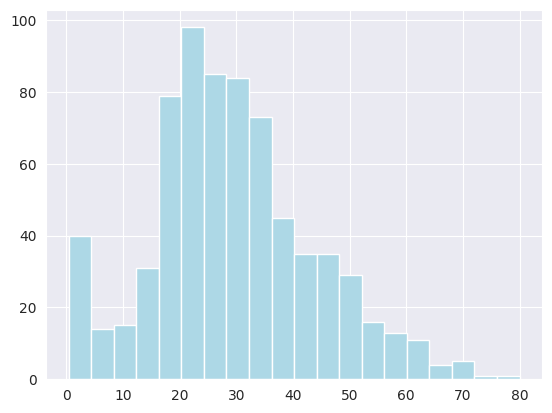

In [ ]:
titanic_data['age'].hist(bins=20, color='lightblue')
plt.show()

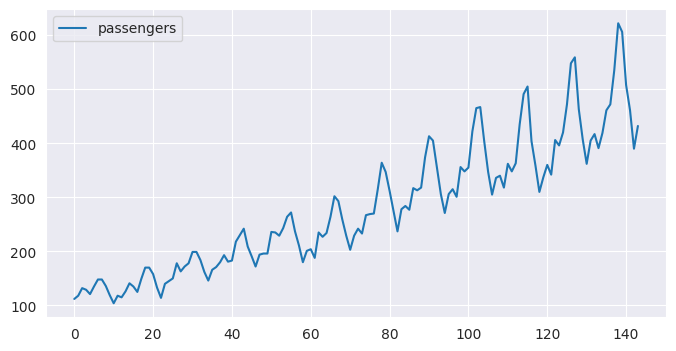

In [ ]:
flights_data.plot.line(y='passengers', figsize=(8, 4))
plt.show()

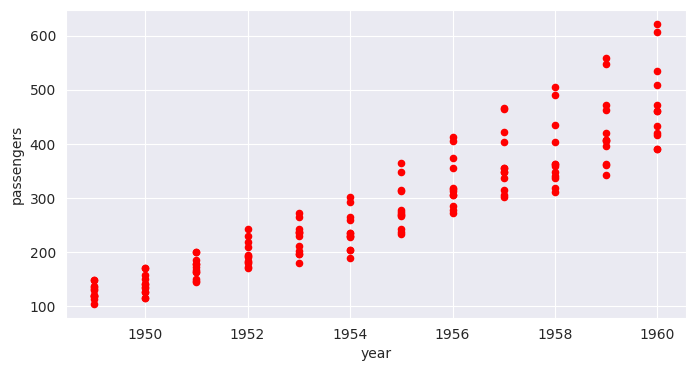

In [ ]:
flights_data.plot.scatter(x='year', y='passengers', color='red', figsize=(8, 4))
plt.show()

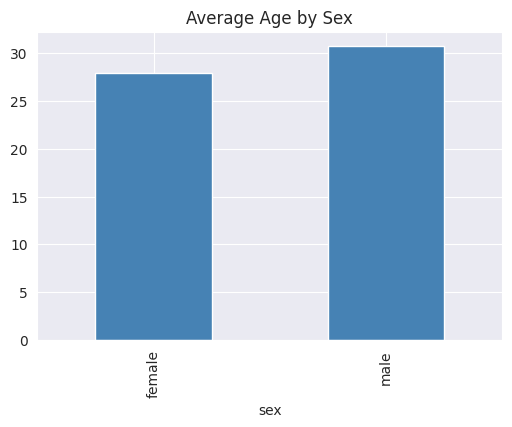

In [ ]:
sex_mean = titanic_data.groupby("sex", observed=False)["age"].mean()
sex_mean.plot(kind='bar', color='steelblue', title='Average Age by Sex', figsize=(6, 4))
plt.show()

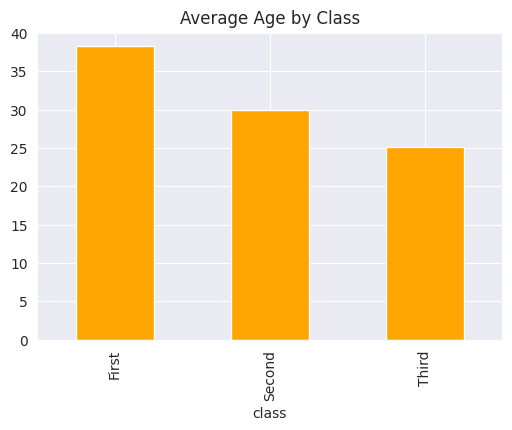

In [ ]:
class_mean = titanic_data.groupby("class", observed=False)["age"].mean()
class_mean.plot(kind='bar', color='orange', title='Average Age by Class', figsize=(6, 4))
plt.show()

created a new graph that sorted age according to class

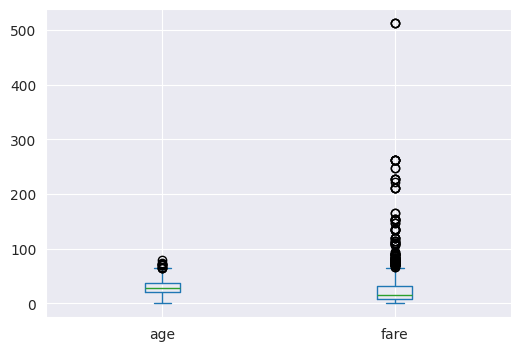

In [ ]:
titanic_data[['age', 'fare']].plot.box(figsize=(6, 4))
plt.show()

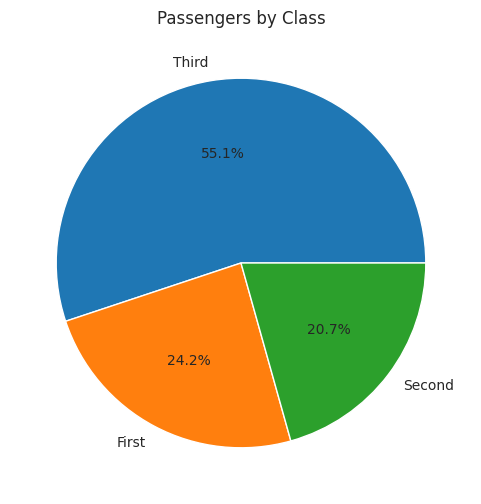

In [ ]:
titanic_data["class"].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(6, 6),
    title='Passengers by Class'
)
plt.ylabel('')
plt.show()

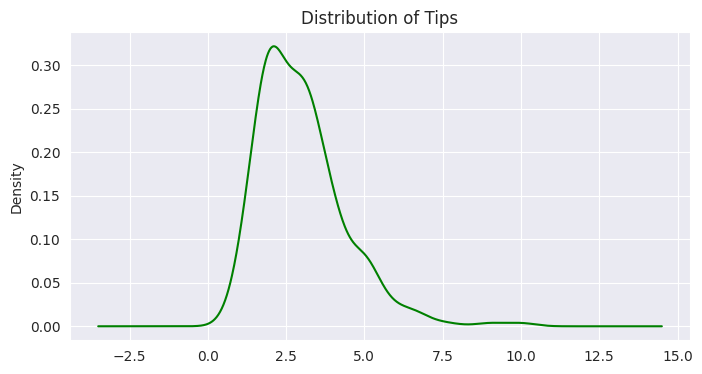

In [ ]:
tips_data = sns.load_dataset('tips')
tips_data['tip'].plot.kde(figsize=(8, 4), color='green', title='Distribution of Tips')
plt.show()

In [ ]:
dates = pd.date_range(start='2021-01-01', end='2021-06-30')
print(len(dates))

181


In [ ]:
date_df = pd.DataFrame({'Date': dates})
date_df['Temperature'] = np.random.randint(0, 50, size=len(dates))
date_df.head()

,Date,Temperature
0,2021-01-01,13
1,2021-01-02,40
2,2021-01-03,12
3,2021-01-04,39
4,2021-01-05,42


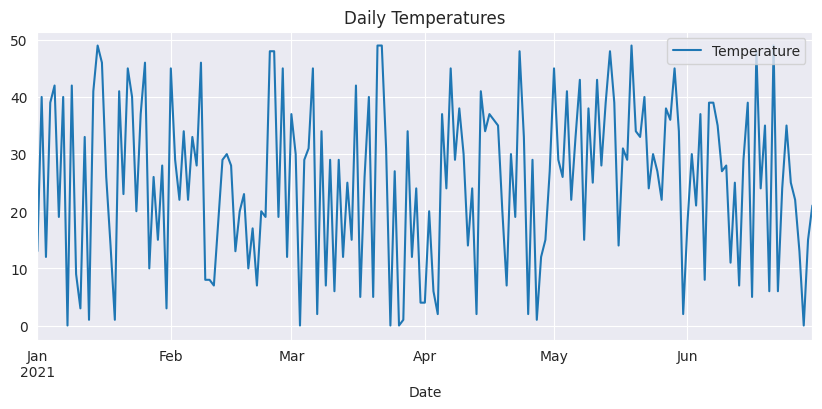

In [ ]:
date_df.plot.line(x='Date', y='Temperature', figsize=(10, 4), title='Daily Temperatures')
plt.show()

In [ ]:
url = "https://raw.githubusercontent.com/duochen/data-science-bootcamp/refs/heads/main/Data/google_stock_prices.csv"

google_stock = pd.read_csv(url)
google_stock['Date'] = pd.to_datetime(google_stock['Date'])
google_stock.set_index('Date', inplace=True)
google_stock.head()

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2004-08-19,50.050049,52.082081,48.028027,50.220219,50.220219,44659096
2004-08-20,50.555557,54.594597,50.300301,54.209209,54.209209,22834343
2004-08-23,55.430431,56.796799,54.579578,54.754753,54.754753,18256126
2004-08-24,55.675674,55.855858,51.836838,52.487488,52.487488,15247337
2004-08-25,52.532532,54.054054,51.991993,53.053055,53.053055,9188602


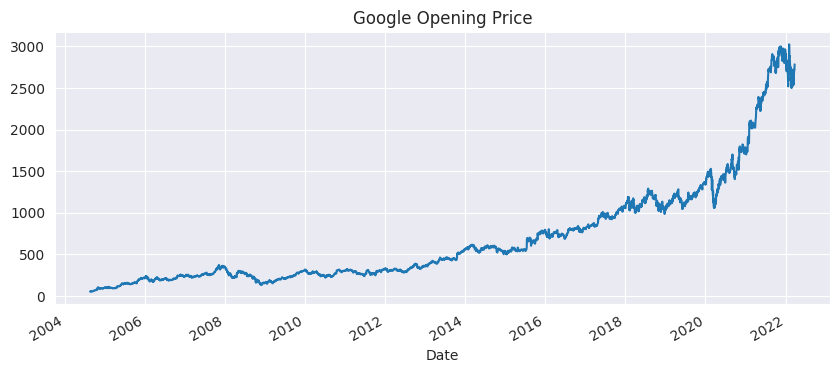

In [ ]:
google_stock['Open'].plot(figsize=(10, 4), title='Google Opening Price')
plt.show()

In [ ]:
yearly_open = google_stock['Open'].resample('YE').mean()
yearly_open

,Open
Date,
2004-12-31,75.791855
2005-12-31,139.004739
2006-12-31,206.155438
2007-12-31,269.683608
2008-12-31,233.369932
2009-12-31,219.704962
2010-12-31,268.424416
2011-12-31,284.870722
2012-12-31,321.716956


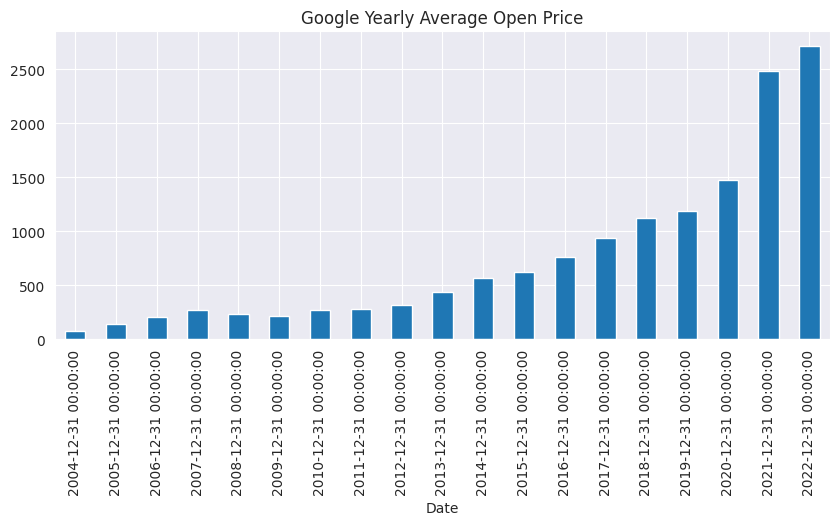

In [ ]:
yearly_open.plot(kind='bar', figsize=(10, 4), title='Google Yearly Average Open Price')
plt.show()

In [ ]:
google_stock['Prev Open'] = google_stock['Open'].shift(1)
google_stock[['Open', 'Prev Open']].head()

,Open,Prev Open
Date,,
2004-08-19,50.050049,NaN
2004-08-20,50.555557,50.050049
2004-08-23,55.430431,50.555557
2004-08-24,55.675674,55.430431
2004-08-25,52.532532,55.675674


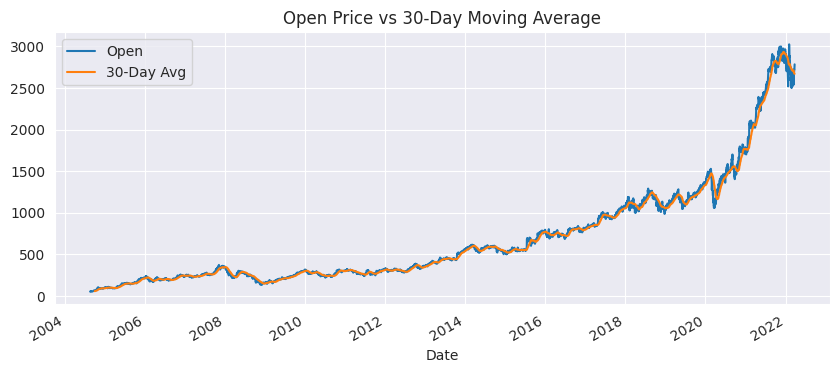

In [ ]:
google_stock['30-Day Avg'] = google_stock['Open'].rolling(window=30).mean()
google_stock[['Open', '30-Day Avg']].plot(figsize=(10, 4), title='Open Price vs 30-Day Moving Average')
plt.show()